# 3. Fixing the candidate lists without retraining

If the errors are shared spelling variants, adding the missing variants to the candidate list should raise the
ceiling, and a word n-gram language model built from the training text can then choose among them. All settings were
tuned on DL Sprint dev only and applied unchanged to every test set.

In [1]:
from nbutil import *
import pandas as pd

In [2]:
s = pd.read_csv(ROOT / "results/list_correction/summary.csv").set_index("set")
cols = {"greedy_wer": "greedy", "mbr_lm_wer": "LM-MBR on the list", "rewrite_wer": "rewrite rules",
        "mbr_lm_x_wer": "LM-MBR on the expanded list", "oracle_pool_wer": "oracle before", "oracle_x_wer": "oracle after expansion"}
(100 * s[list(cols)]).rename(columns=cols).round(2)

,greedy,LM-MBR on the list,rewrite rules,LM-MBR on the expanded list,oracle before,oracle after expansion
set,,,,,,
splits_fa-dev,29.33,27.97,24.69,23.80,24.00,19.59
splits_fa-eval,22.71,21.55,17.58,17.46,18.35,13.75
fleurs-test,21.54,20.25,20.23,19.48,16.34,14.66
kathbath-valid,14.80,14.16,15.22,14.25,9.28,8.72


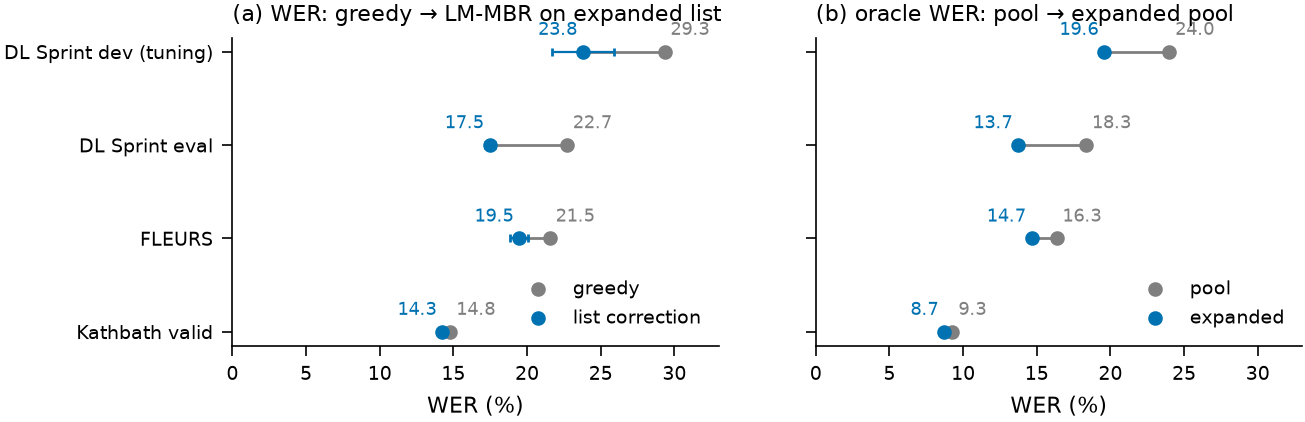

In [3]:
figure("f6_list_correction")

The settings chosen on DL Sprint dev:

In [4]:
load("results/list_correction/tuned.json")

{'meta': {'tuned_on': 'splits_fa-dev',
  'lm_order': 4,
  'dev_perplexity_by_order': {'2': 1419.125882117399,
   '3': 1396.1123335657612,
   '4': 1387.9428647134896},
  'lm_text': 'data/splits_fa/train_clean.csv',
  'lm_sentences': 15325,
  'n_rules': 3423,
  'rule_source': 'results/zeroshot/splits_fa-train/bengaliAI__tugstugi_bengaliai-regional-asr_whisper-medium/predictions.jsonl',
  'n_boot': 2000,
  'normalizer': 'bangla_asr.common.text.normalize_bangla_text'},
 'tuned': {'greedy': {},
  'am': {'order': 2, 'lam': 0, 'beta': 0},
  'lm': {'order': 4, 'lam': 0.5, 'beta': 4},
  'mbr_lm': {'order': 4, 'lam': 0.5, 'beta': 4, 'T': 0.5},
  'rover': {'order': 4, 'lam': 0.5, 'beta': 4, 'T': 16},
  'rewrite': {'rules': 'all|2|0.5'},
  'rewrite_sel': {'rules': 'all|2|0.5', 'max_agree': 12},
  'lm_x': {'order': 4, 'lam': 0.2, 'beta': 2},
  'mbr_lm_x': {'order': 4, 'lam': 0.5, 'beta': 4, 'T': 4}}}

In [5]:
record("results/list_correction/run_info.json")

**Run record** `results/list_correction/run_info.json`  
`python.exe pipeline/12_raise_ceiling.py`  
commit `0233644c1e` · started 2026-10-09T21:45:56 · 238.2 s · torch 2.13.0+cu126, transformers 5.15.0, GPU NVIDIA GeForce RTX 3060

**Next:** without retraining the speech model, WER on media speech falls from 22.7% to 17.5%, and expanding the list
lowers the oracle from 18.3% to 13.7%. The stronger fix is to teach the model the corpus's spelling: notebook 4.